**CADEN SAMPSON**
**ST10143759**
**PDAN8412**
**PORTFOLIO OF EVIDENCE**

In [ ]:
#Import necessary libraries

import tensorflow as tf #TensorFlow for deep learning
from tensorflow.keras import layers, models #Keras layers and models
from tensorflow.keras.callbacks import EarlyStopping #EarlyStopping for training

import pandas as pd #Pandas for data manipulation
import matplotlib.pyplot as plt #Matplotlib for plotting
import os #Operating system interface
import numpy as np #NumPy for numerical operations
from pathlib import Path #Pathlib for filesystem paths
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay #Scikit-learn metrics for evaluation

from PIL import Image #Pillow for image processing
import random #Random for random operations


In [48]:
#Import the dataset
base_dir = r"C:\Users\caden\Downloads\archive (17)\real_vs_fake\real-vs-fake"
train_dir = os.path.join(base_dir, "train")
val_dir   = os.path.join(base_dir, "valid")
test_dir  = os.path.join(base_dir, "test")

Exploratory Data Analysis 

In [49]:
#Load the image splits directly from their subfolders
IMG_SIZE = (128, 128)
BATCH_SIZE = 64

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False  # Keep test order fixed for confusion matrix & classification report
)

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.


In [50]:
#Verify class mapping (alphabetical: 0 = 'fake', 1 = 'real')
print("Class names:", train_ds.class_names)

Class names: ['fake', 'real']


Dataset Distribution: {'Train': {'real': 50000, 'fake': 50000}, 'Validation': {'real': 10000, 'fake': 10000}, 'Test': {'real': 10000, 'fake': 10000}}


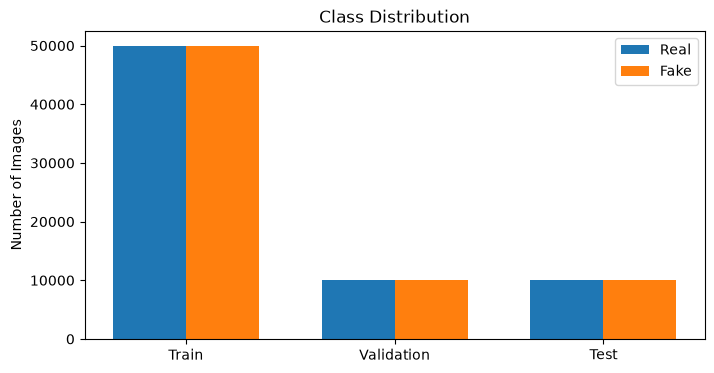

In [ ]:
# Count images per class in each split to verify class balance and dataset size

splits = {"Train": train_dir, "Validation": val_dir, "Test": test_dir}
counts = {split: {} for split in splits}

for split_name, split_path in splits.items():
    for cls in ["real", "fake"]:
        cls_path = os.path.join(split_path, cls)
        counts[split_name][cls] = len(os.listdir(cls_path))

print("Dataset Distribution:", counts)

# Visualize class distribution across splits for the client report
labels = list(splits.keys())
real_counts = [counts[s]["real"] for s in labels]
fake_counts = [counts[s]["fake"] for s in labels]

x = np.arange(len(labels))
width = 0.35
plt.figure(figsize=(8, 4))
plt.bar(x - width/2, real_counts, width, label="Real")
plt.bar(x + width/2, fake_counts, width, label="Fake")
plt.xticks(x, labels)
plt.ylabel("Number of Images")
plt.title("Class Distribution")
plt.legend()
plt.show()

#Reference: https://www.rasa-ai.com/wp-content/uploads/2022/02/Aur%C3%A9lien-G%C3%A9ron-Hands-On-Machine-Learning-with-Scikit-Learn-Keras-and-Tensorflow_-Concepts-Tools-and-Techniques-to-Build-Intelligent-Systems-O%E2%80%99Reilly-Media-2019.pdf

In [ ]:
# Check for image shape and mode consistency, and identify any corrupted files

shapes, modes, corrupted = set(), set(), []

for split in splits:
    for cls in classes:
        folder = os.path.join(base_dir, split, cls)
        # Sample 1,000 images per folder for a fast check (or remove slice to check all 140k)
        files = os.listdir(folder)[:1000]
        for f in files:
            path = os.path.join(folder, f)
            try:
                with Image.open(path) as img:
                    shapes.add(img.size)
                    modes.add(img.mode)
            except Exception:
                corrupted.append(path)

print("Unique image resolutions (W, H):", shapes)
print("Unique color modes:", modes)
print("Corrupted files found:", len(corrupted))

#Reference: https://sourestdeeds.github.io/pdf/Deep%20Learning%20with%20Python.pdf 

Unique image resolutions (W, H): {(256, 256)}
Unique color modes: {'RGB'}
Corrupted files found: 0


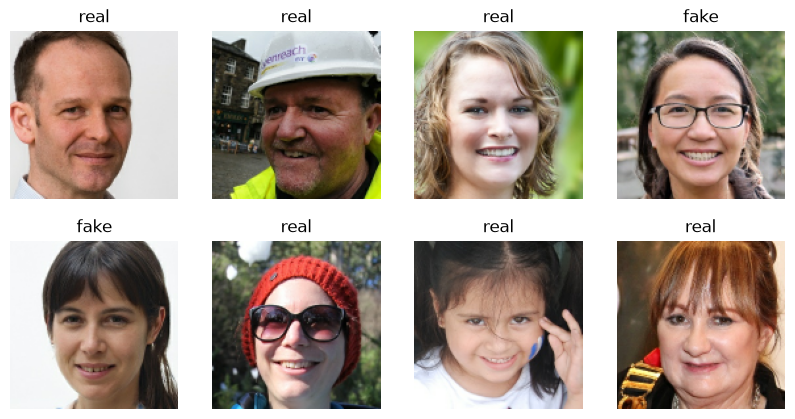

In [ ]:
# Visualize a sample grid of 8 training images with labels 
class_names = train_ds.class_names
plt.figure(figsize=(10, 5))
for images, lbls in train_ds.take(1):
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        # Index [0] extracts the scalar value from the (1,) binary label tensor
        plt.title(class_names[int(lbls[i][0])])
        plt.axis("off")
plt.show()

#References: https://openaccess.thecvf.com/content_CVPR_2019/papers/Karras_A_Style-Based_Generator_Architecture_for_Generative_Adversarial_Networks_CVPR_2019_paper.pdf 


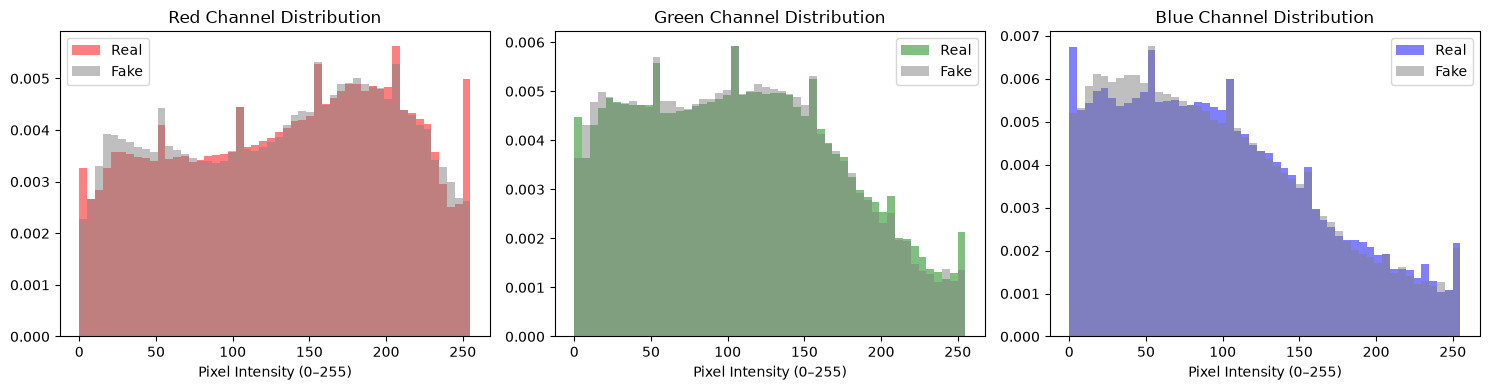

In [57]:
#RGB pixel intensity distribution analysis for real vs. fake images

def get_channel_means(cls, n_samples=500):
    folder = os.path.join(base_dir, "train", cls)
    files = random.sample(os.listdir(folder), n_samples)
    pixels = np.array([np.array(Image.open(os.path.join(folder, f)).resize((128, 128))) for f in files])
    return pixels  

real_px = get_channel_means("real")
fake_px = get_channel_means("fake")

colors = ["red", "green", "blue"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(colors):
    axes[i].hist(real_px[..., i].ravel(), bins=50, alpha=0.5, label="Real", color=col, density=True)
    axes[i].hist(fake_px[..., i].ravel(), bins=50, alpha=0.5, label="Fake", color="gray", density=True)
    axes[i].set_title(f"{col.capitalize()} Channel Distribution")
    axes[i].set_xlabel("Pixel Intensity (0–255)")
    axes[i].legend()

plt.tight_layout()
plt.show()

#Reference: https://www.researchgate.net/publication/335539059_Detecting_GAN-Generated_Imagery_Using_Saturation_Cues

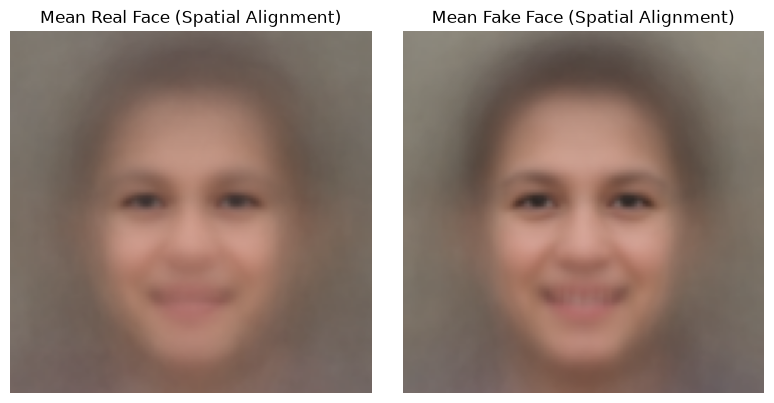

In [ ]:
# Visualize the mean face for real vs. fake images to highlight spatial alignment differences
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(real_px.mean(axis=0).astype("uint8"))
axes[0].set_title("Mean Real Face (Spatial Alignment)")
axes[0].axis("off")

axes[1].imshow(fake_px.mean(axis=0).astype("uint8"))
axes[1].set_title("Mean Fake Face (Spatial Alignment)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Optimize disk-to-GPU/CPU data pipeline performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

#Reference: https://www.tensorflow.org/guide/data_performance 

Baseline Model

In [ ]:
# FEATURE EXTRACTION & BASELINE CNN ARCHITECTURE

baseline_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),

    # Convolutional and MaxPooling blocks extract hierarchical facial edges, textures, and GAN artifacts
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # GlobalAveragePooling2D condenses feature maps without creating excessive parameters
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")  # Sigmoid outputs probability for binary classification
])

#Reference: https://arxiv.org/pdf/1312.4400 

In [ ]:
# Compile using Adam optimizer and binary cross-entropy loss
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

#Reference: https://arxiv.org/pdf/1412.6980

In [ ]:
#TRAIN BASELINE MODEL
history_base = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15


c:\Users\caden\anaconda3\envs\Spark\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 781s 498ms/step - accuracy: 0.5749 - loss: 0.6710 - val_accuracy: 0.6423 - val_loss: 0.6353
Epoch 2/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 717s 458ms/step - accuracy: 0.6857 - loss: 0.5919 - val_accuracy: 0.7041 - val_loss: 0.5691
Epoch 3/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 777s 497ms/step - accuracy: 0.7438 - loss: 0.5191 - val_accuracy: 0.7643 - val_loss: 0.4876
Epoch 4/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 798s 511ms/step - accuracy: 0.7743 - loss: 0.4750 - val_accuracy: 0.7733 - val_loss: 0.4754
Epoch 5/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 868s 555ms/step - accuracy: 0.7983 - loss: 0.4361 - val_accuracy: 0.8079 - val_loss: 0.4178
Epoch 6/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 838s 536ms/step - accuracy: 0.8161 - loss: 0.4052 - val_accuracy: 0.8259 - val_loss: 0.3854
Epoch 7/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 820s 525ms/step - accuracy: 0.8344 - loss: 0.3717 - val_accuracy: 0.8379 - val_loss: 0.3622
Epoch 8/15
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 810s 518ms/step - accuracy: 0.8

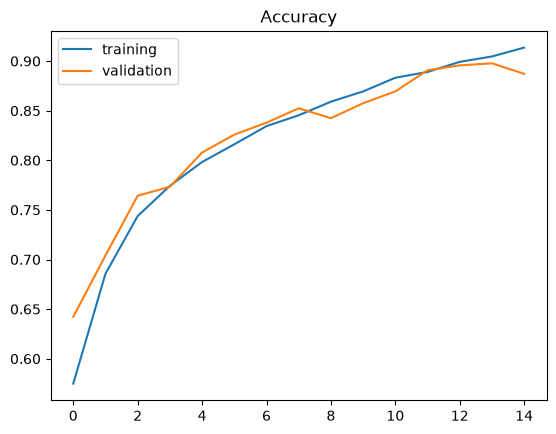

In [52]:
# Visualize training and validation accuracy over epochs to assess model performance
plt.plot(history_base.history['accuracy'], label='training')
plt.plot(history_base.history['val_accuracy'], label='validation')
plt.legend()
plt.title('Accuracy')
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 64s 204ms/step - accuracy: 0.8874 - loss: 0.2709

Baseline Model Test Accuracy: 88.74%
Baseline Model Test Loss:     0.2709

Baseline Model Classification Report:
              precision    recall  f1-score   support

        fake       0.84      0.95      0.89     10000
        real       0.94      0.82      0.88     10000

    accuracy                           0.89     20000
   macro avg       0.89      0.89      0.89     20000
weighted avg       0.89      0.89      0.89     20000



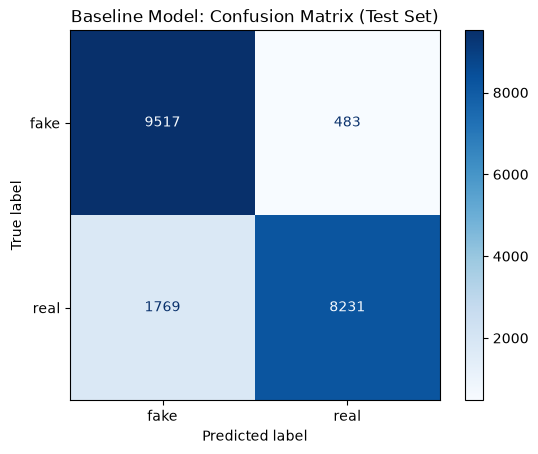

In [ ]:
#Test Baseline model against test dataset to evaluate its performance on unseen data

# Save baseline weights to disk 
baseline_model.save("baseline_face_cnn.keras")

# Evaluate baseline model on the unseen test set
test_loss, test_acc = baseline_model.evaluate(test_ds, verbose=1)
print(f"\nBaseline Model Test Accuracy: {test_acc * 100:.2f}%")
print(f"Baseline Model Test Loss:     {test_loss:.4f}")

# Collect true labels and predictions batch-by-batch so order stays aligned
y_true = []
y_pred_probs_base = []

for images, labels in test_ds:
    y_true.extend(labels.numpy())
    preds = baseline_model.predict(images, verbose=0)
    y_pred_probs_base.extend(preds.flatten())

y_true = np.array(y_true)
y_pred_base = (np.array(y_pred_probs_base) > 0.5).astype("int32")

class_names = getattr(test_ds, "class_names", ["fake", "real"])

# Print Baseline Classification Report
print("\nBaseline Model Classification Report:")
print(classification_report(y_true, y_pred_base, target_names=class_names))

# Plot Baseline Confusion Matrix
cm_base = confusion_matrix(y_true, y_pred_base)
disp_base = ConfusionMatrixDisplay(confusion_matrix=cm_base, display_labels=class_names)
disp_base.plot(cmap="Blues")
plt.title("Baseline Model: Confusion Matrix (Test Set)")
plt.show()

Tuned Model 

In [ ]:
# BUILD THE TUNED CNN ARCHITECTURE

tuned_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Subtle horizontal flip creates realistic mirrored faces without distorting facial geometry
    layers.RandomFlip("horizontal"),
    layers.Rescaling(1./255),

    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification head with Dropout regularization
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),  # Drops 30% of neurons during training to improve generalization
    layers.Dense(1, activation="sigmoid")
])

#Reference: 
# https://www.cs.toronto.edu/~rsalakhu/papers/srivastava14a.pdf
# https://link.springer.com/article/10.1186/s40537-019-0197-0 


In [ ]:
# COMPILE TUNED MODEL WITH LOWER LEARNING RATE

tuned_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# EarlyStopping halts training if validation loss does not improve for 2 consecutive epochs
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

#Reference: https://link.springer.com/chapter/10.1007/3-540-49430-8_3 

In [ ]:
# RETRAIN TUNED MODEL
history_tuned = tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10


c:\Users\caden\anaconda3\envs\Spark\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1834s 1s/step - accuracy: 0.5769 - loss: 0.6741 - val_accuracy: 0.6276 - val_loss: 0.6436
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 800s 511ms/step - accuracy: 0.6659 - loss: 0.6119 - val_accuracy: 0.7035 - val_loss: 0.5689
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 788s 504ms/step - accuracy: 0.7290 - loss: 0.5414 - val_accuracy: 0.7539 - val_loss: 0.5083
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 803s 514ms/step - accuracy: 0.7586 - loss: 0.4988 - val_accuracy: 0.7594 - val_loss: 0.4947
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 808s 517ms/step - accuracy: 0.7844 - loss: 0.4603 - val_accuracy: 0.8069 - val_loss: 0.4215
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 849s 543ms/step - accuracy: 0.8092 - loss: 0.4217 - val_accuracy: 0.8293 - val_loss: 0.3841
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 757s 484ms/step - accuracy: 0.8295 - loss: 0.3856 - val_accuracy: 0.8446 - val_loss: 0.3547
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 758s 485ms/step - accuracy: 0.846

In [27]:
tuned_model.save("tuned_face_cnn_10ep.keras")

In [28]:
# Continue training from Epoch 10 weights for 5 more epochs (15 total)
history_tuned_part2 = tuned_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop]
)

# Save the final 15-epoch weights once finished
tuned_model.save("tuned_face_cnn_15ep.keras")

Epoch 1/5


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 746s 478ms/step - accuracy: 0.8796 - loss: 0.2879 - val_accuracy: 0.8729 - val_loss: 0.2964
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 758s 485ms/step - accuracy: 0.8906 - loss: 0.2672 - val_accuracy: 0.8620 - val_loss: 0.3160
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 756s 484ms/step - accuracy: 0.8939 - loss: 0.2553 - val_accuracy: 0.8916 - val_loss: 0.2568
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1157s 740ms/step - accuracy: 0.9017 - loss: 0.2404 - val_accuracy: 0.8997 - val_loss: 0.2407
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1037s 663ms/step - accuracy: 0.9061 - loss: 0.2321 - val_accuracy: 0.9062 - val_loss: 0.2268


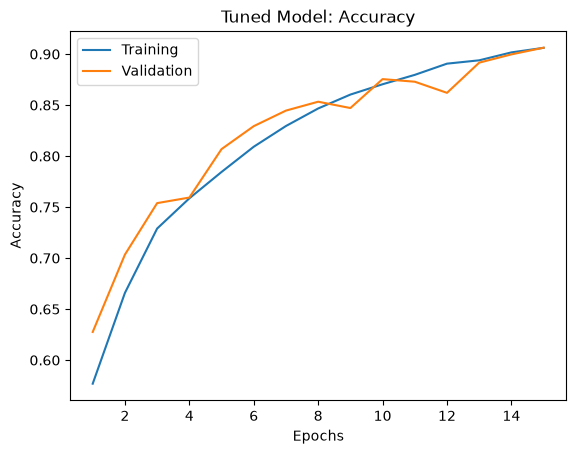

In [53]:
#Visualize training and validation accuracy over epochs to assess model performance

full_acc = history_tuned.history["accuracy"] + history_tuned_part2.history["accuracy"]
full_val_acc = history_tuned.history["val_accuracy"] + history_tuned_part2.history["val_accuracy"]

plt.plot(range(1, len(full_acc) + 1), full_acc, label="Training")
plt.plot(range(1, len(full_val_acc) + 1), full_val_acc, label="Validation")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Tuned Model: Accuracy")
plt.legend()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 52s 166ms/step - accuracy: 0.9053 - loss: 0.2323

Tuned Model Test Accuracy: 90.53%
Tuned Model Test Loss:     0.2323

Tuned Model Classification Report:
              precision    recall  f1-score   support

        fake       0.90      0.91      0.91     10000
        real       0.91      0.90      0.90     10000

    accuracy                           0.91     20000
   macro avg       0.91      0.91      0.91     20000
weighted avg       0.91      0.91      0.91     20000



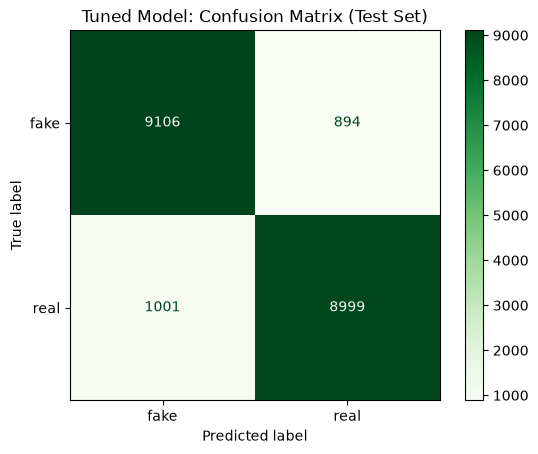

In [ ]:
# Evaluate the tuned model on the unseen test set

# Calculate overall test loss and accuracy on the 20,000 unseen test images
tuned_loss, tuned_acc = tuned_model.evaluate(test_ds, verbose=1)
print(f"\nTuned Model Test Accuracy: {tuned_acc * 100:.2f}%")
print(f"Tuned Model Test Loss:     {tuned_loss:.4f}")

# Collect true labels and predictions together so batch order always stays aligned
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    y_true.extend(labels.numpy())
    preds = tuned_model.predict(images, verbose=0)
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true)
y_pred = (np.array(y_pred_probs) > 0.5).astype("int32")

# Safely get class names (defaults to ['fake', 'real'] if test_ds was wrapped with .prefetch())
class_names = getattr(test_ds, "class_names", ["fake", "real"])

# Print Precision, Recall, and F1-Score
print("\nTuned Model Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Greens")
plt.title("Tuned Model: Confusion Matrix (Test Set)")
plt.show()

In [ ]:
#Compare baseline and tuned model performance on the final test set
print("FINAL TEST SET COMPARISON")
print(f"Baseline Model Accuracy: {test_acc * 100:.2f}%  Loss: {test_loss:.4f}")
print(f"Tuned Model Accuracy: {tuned_acc * 100:.2f}% Loss: {tuned_loss:.4f}")

FINAL TEST SET COMPARISON
Baseline Model Accuracy: 88.74%  Loss: 0.2709
Tuned Model Accuracy: 90.53% Loss: 0.2323


In [ ]:
#Save the final tuned model to disk for future inference or deployment

save_path = r"C:\Users\caden\OneDrive\Documents\Programming - PDAN8412\POE\tuned_face_cnn_15ep.keras"
tuned_model.save(save_path)

print("Saved successfully:", os.path.exists(save_path))

Saved successfully: True
